# Module 9 — Data Visualisation with Matplotlib

**Python for Machine Learning · MSc Artificial Intelligence · Swansea University**

---

## Learning objectives

1. Understand Matplotlib's two interfaces and the **Figure / Axes** model.
2. Create line plots, scatter plots, histograms, bar charts, box plots and heatmaps.
3. Customise titles, labels, legends, colours, limits and styles; build multi-panel figures.
4. Choose the right chart for the question and follow good design principles.
5. Produce ML-specific plots: training curves, feature distributions, correlation matrices, decision boundaries.

---

## 9.1 Why visualise?

Visualisation is how you **understand data before modelling** and **diagnose models after training**. Summary statistics can hide very different data (look up *Anscombe's quartet*). In ML you will constantly plot:

* feature distributions and relationships (exploration);
* training and validation loss per epoch (is the model over-fitting?);
* predictions versus true values, residuals, confusion matrices (evaluation).

## 9.2 Figures and Axes

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# A colourblind-friendly colour order for the whole course (blue, orange, aqua, yellow, magenta, green)
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=COLORS),
    "figure.figsize": (7, 4),
    "axes.spines.top": False,          # remove clutter
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

A **Figure** is the whole canvas; an **Axes** is one plot inside it (with its own x-axis, y-axis, title…). A figure can contain many axes.

Matplotlib has two interfaces:

* **pyplot (state-based):** `plt.plot(...)`, `plt.title(...)` — acts on the "current" axes. Quick for one plot.
* **Object-oriented (recommended):** `fig, ax = plt.subplots()` then `ax.plot(...)`, `ax.set_title(...)`. Explicit and scales to multi-panel figures.

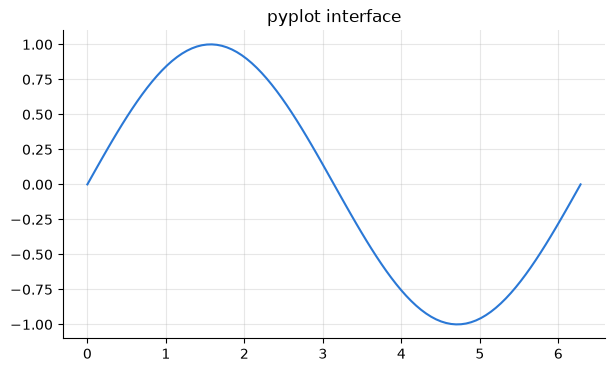

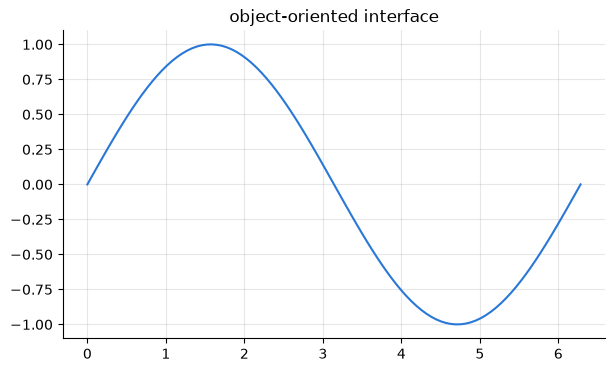

In [4]:
x = np.linspace(0, 2 * np.pi, 100)

# pyplot style
plt.plot(x, np.sin(x))
plt.title("pyplot interface")
plt.show()

# object-oriented style
fig, ax = plt.subplots()
ax.plot(x, np.sin(x))
ax.set_title("object-oriented interface")
plt.show()

We'll use the object-oriented style from here on.

## 9.3 Line plots

Use line plots for something that changes over an **ordered** variable (time, epochs, a parameter).

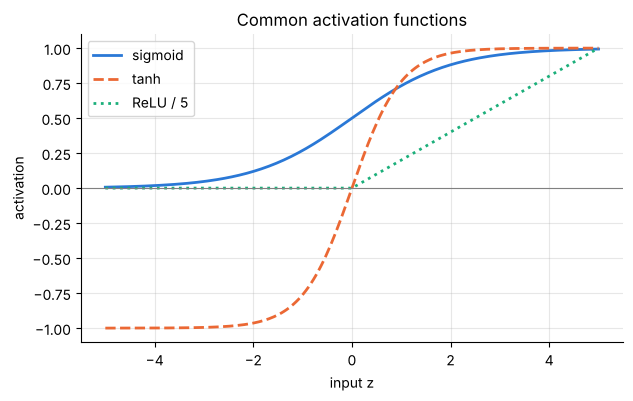

In [3]:
x = np.linspace(-5, 5, 200)
fig, ax = plt.subplots()
ax.plot(x, 1 / (1 + np.exp(-x)), label="sigmoid", linewidth=2)
ax.plot(x, np.tanh(x), label="tanh", linewidth=2, linestyle="--")
ax.plot(x, np.maximum(0, x) / 5, label="ReLU / 5", linewidth=2, linestyle=":")
ax.set_xlabel("input z")
ax.set_ylabel("activation")
ax.set_title("Common activation functions")
ax.set_ylim(-1.1, 1.1)
ax.axhline(0, color="gray", linewidth=0.8)    # horizontal reference line
ax.legend()
plt.show()

Common formatting options: `color=`, `linewidth=` (`lw`), `linestyle=` (`'-'`, `'--'`, `':'`, `'-.'`), `marker=` (`'o'`, `'s'`, `'^'`), `markersize=`, `alpha=` (transparency), `label=` (for the legend).

### Training curves

The most important diagnostic plot in ML. Here we simulate a model that starts over-fitting:

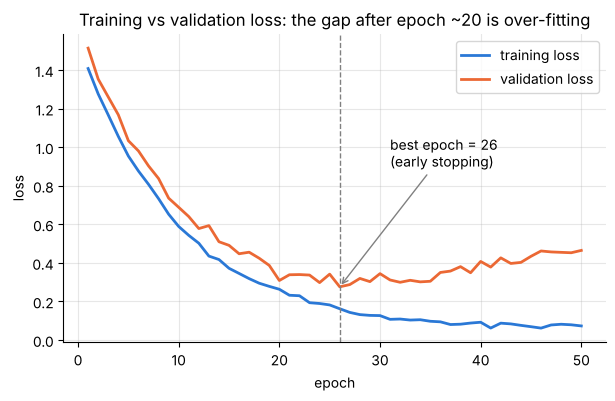

In [4]:
epochs = np.arange(1, 51)
rng = np.random.default_rng(0)
train_loss = 1.5 * np.exp(-epochs / 10) + 0.05 + rng.normal(0, 0.01, 50)
val_loss = 1.5 * np.exp(-epochs / 10) + 0.15 + 0.004 * np.maximum(0, epochs - 20) ** 1.3 + rng.normal(0, 0.02, 50)
best = epochs[np.argmin(val_loss)]

fig, ax = plt.subplots()
ax.plot(epochs, train_loss, label="training loss", lw=2)
ax.plot(epochs, val_loss, label="validation loss", lw=2)
ax.axvline(best, color="gray", linestyle="--", lw=1)
ax.annotate(f"best epoch = {best}\n(early stopping)", xy=(best, val_loss.min()),
            xytext=(best + 5, 0.9), arrowprops=dict(arrowstyle="->", color="gray"))
ax.set_xlabel("epoch")
ax.set_ylabel("loss")
ax.set_title("Training vs validation loss: the gap after epoch ~20 is over-fitting")
ax.legend()
plt.show()

## 9.4 Scatter plots

Use scatter plots for the **relationship between two numeric variables**. Colour can encode a third, categorical, variable.

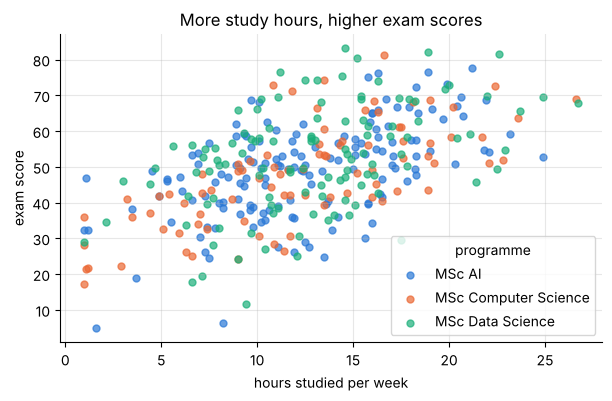

In [5]:
df = pd.read_csv("../data/student_performance.csv").drop_duplicates().dropna()
df["study_mode"] = df["study_mode"].str.strip().str.capitalize()   # quick clean-up (see Module 8)

fig, ax = plt.subplots()
for programme, group in df.groupby("programme"):
    ax.scatter(group["hours_studied"], group["exam_score"], label=programme, alpha=0.7, s=25)
ax.set_xlabel("hours studied per week")
ax.set_ylabel("exam score")
ax.set_title("More study hours, higher exam scores")
ax.legend(title="programme")
plt.show()

Colour can also encode a **continuous** variable through a *colormap* plus a colour bar:

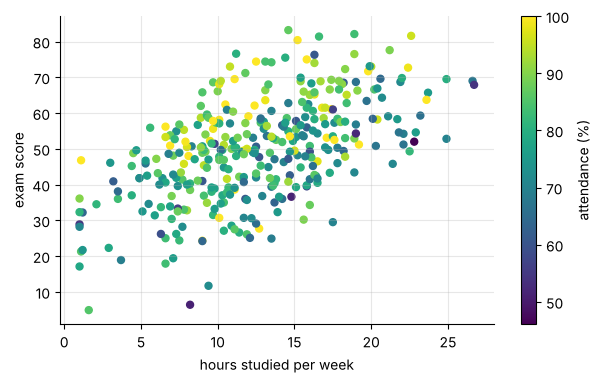

In [6]:
fig, ax = plt.subplots()
sc = ax.scatter(df["hours_studied"], df["exam_score"], c=df["attendance_pct"], cmap="viridis", s=25)
fig.colorbar(sc, ax=ax, label="attendance (%)")
ax.set_xlabel("hours studied per week")
ax.set_ylabel("exam score")
plt.show()

**Choosing a colormap**

* **Sequential** (one direction, low → high): `viridis`, `Blues`. Use for magnitudes.
* **Diverging** (two directions from a meaningful centre, e.g. 0): `RdBu`, `coolwarm`. Use for correlations, residuals.
* **Avoid rainbow maps** like `jet`: they create fake boundaries and are unreadable for colourblind viewers.

## 9.5 Histograms

Histograms show the **distribution** of one numeric variable. The number of `bins` changes what you see — try a few.

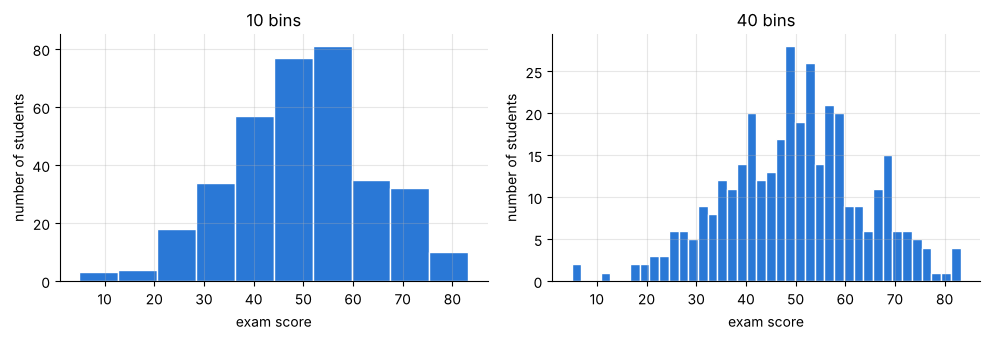

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(df["exam_score"], bins=10, edgecolor="white")
axes[0].set_title("10 bins")
axes[1].hist(df["exam_score"], bins=40, edgecolor="white")
axes[1].set_title("40 bins")
for ax in axes:
    ax.set_xlabel("exam score")
    ax.set_ylabel("number of students")
plt.tight_layout()     # avoid overlapping labels
plt.show()

Comparing distributions of two groups — use transparency and `density=True` so that groups of different sizes are comparable:

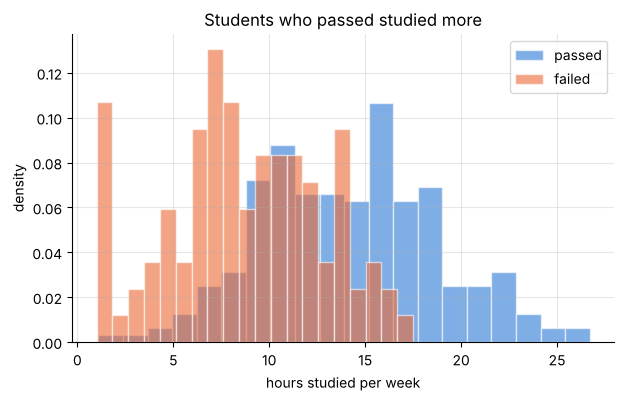

In [8]:
fig, ax = plt.subplots()
for label, name in [(1, "passed"), (0, "failed")]:
    ax.hist(df.loc[df["passed"] == label, "hours_studied"], bins=20, alpha=0.6,
            density=True, label=name, edgecolor="white")
ax.set_xlabel("hours studied per week")
ax.set_ylabel("density")
ax.set_title("Students who passed studied more")
ax.legend()
plt.show()

## 9.6 Bar charts

Bar charts compare **a quantity across categories**. Bars must start at zero.

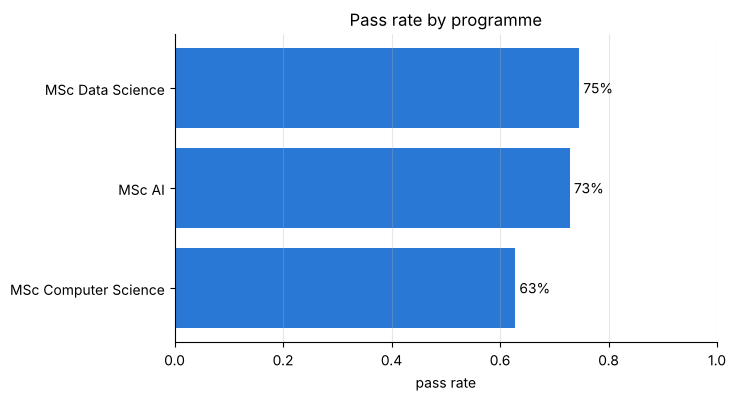

In [9]:
pass_rate = df.groupby("programme")["passed"].mean().sort_values()

fig, ax = plt.subplots()
bars = ax.barh(pass_rate.index, pass_rate.values)          # horizontal: long labels fit better
ax.bar_label(bars, labels=[f"{v:.0%}" for v in pass_rate.values], padding=3)
ax.set_xlabel("pass rate")
ax.set_xlim(0, 1)
ax.set_title("Pass rate by programme")
ax.grid(axis="y", visible=False)
plt.show()

Grouped bars for two categorical variables:

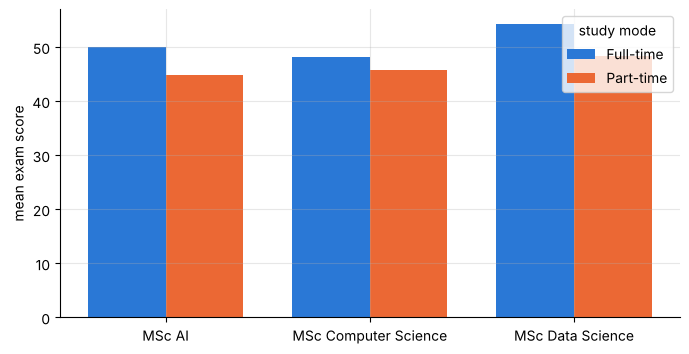

In [10]:
table = df.groupby(["programme", "study_mode"])["exam_score"].mean().unstack()
x = np.arange(len(table.index))
width = 0.38

fig, ax = plt.subplots(figsize=(8, 4))
for i, mode in enumerate(table.columns):
    ax.bar(x + (i - 0.5) * width, table[mode], width=width, label=mode)
ax.set_xticks(x, table.index)
ax.set_ylabel("mean exam score")
ax.legend(title="study mode")
plt.show()

## 9.7 Box plots

A box plot summarises a distribution: the box spans the 25th–75th percentiles, the line is the median, the whiskers extend to 1.5 × IQR, and points beyond are potential **outliers**.

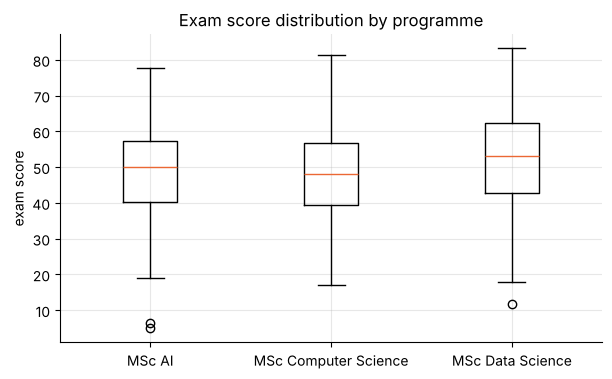

In [11]:
groups = [g["exam_score"].to_numpy() for _, g in df.groupby("programme")]
labels = sorted(df["programme"].unique())

fig, ax = plt.subplots()
ax.boxplot(groups, tick_labels=labels)
ax.set_ylabel("exam score")
ax.set_title("Exam score distribution by programme")
plt.show()

## 9.8 Multi-panel figures

`plt.subplots(nrows, ncols)` returns an array of axes. `sharex`/`sharey` align the scales so panels are comparable.

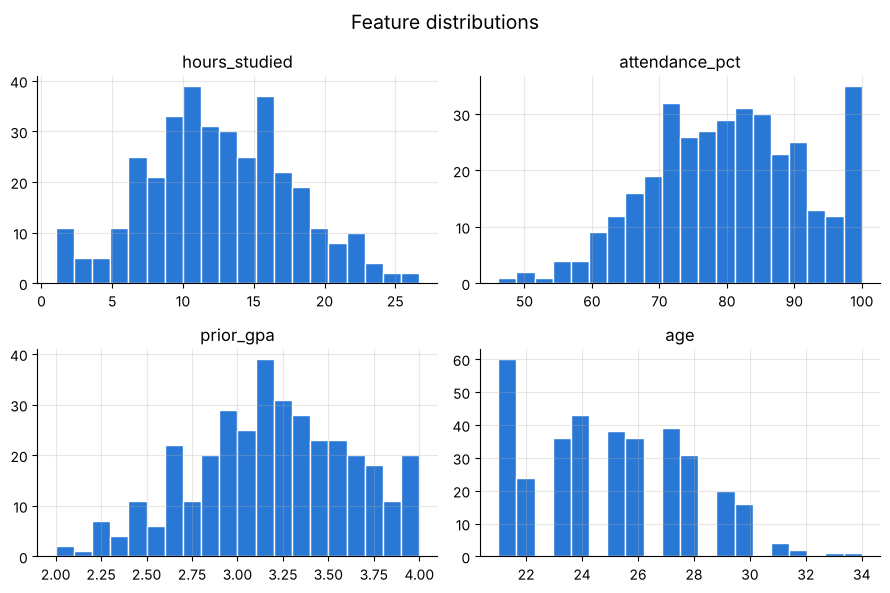

In [12]:
features = ["hours_studied", "attendance_pct", "prior_gpa", "age"]
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
for ax, col in zip(axes.ravel(), features):
    ax.hist(df[col], bins=20, edgecolor="white")
    ax.set_title(col)
fig.suptitle("Feature distributions", fontsize=14)
plt.tight_layout()
plt.show()

> **One measure per y-axis.** If two quantities have different units (e.g. loss and accuracy), put them in **two panels** rather than on a twin y-axis — dual axes are easy to misread.

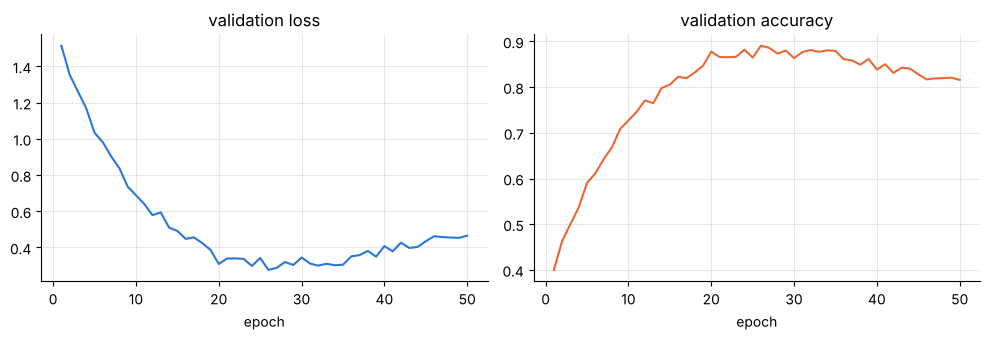

In [13]:
acc = 1 - val_loss / val_loss.max() * 0.6
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5), sharex=True)
ax1.plot(epochs, val_loss)
ax1.set_title("validation loss")
ax2.plot(epochs, acc, color=COLORS[1])
ax2.set_title("validation accuracy")
for ax in (ax1, ax2):
    ax.set_xlabel("epoch")
plt.tight_layout()
plt.show()

## 9.9 Heatmaps and images: `imshow`

### Correlation matrix

Correlations range from −1 to 1 with a meaningful centre at 0, so a **diverging** colormap with symmetric limits is the right choice.

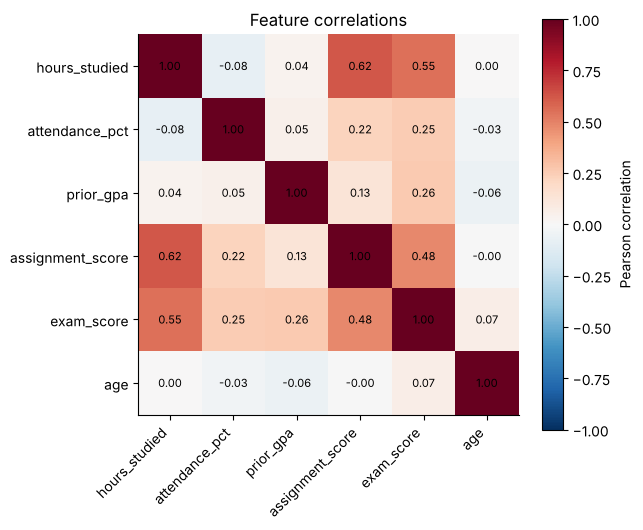

In [14]:
cols = ["hours_studied", "attendance_pct", "prior_gpa", "assignment_score", "exam_score", "age"]
corr = df[cols].corr()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Feature correlations")
plt.tight_layout()
plt.show()

### Images are arrays

A grayscale image is a 2-D array; a colour image is `(height, width, 3)`. This is how computer-vision data looks to a model.

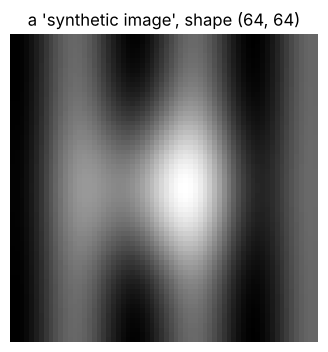

In [15]:
yy, xx = np.mgrid[-1:1:64j, -1:1:64j]
image = np.exp(-(xx ** 2 + yy ** 2) * 4) + 0.3 * np.sin(8 * xx)
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(image, cmap="gray")
ax.set_title(f"a 'synthetic image', shape {image.shape}")
ax.axis("off")
plt.show()

## 9.10 Plotting directly from pandas

pandas has a `.plot` method built on Matplotlib — convenient for quick exploration. It returns an `Axes` you can keep customising:

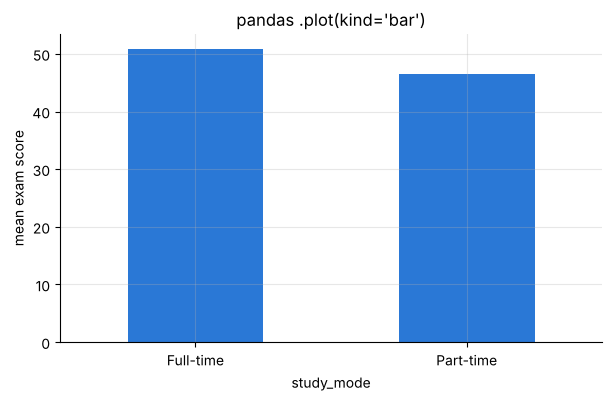

In [16]:
ax = df.groupby("study_mode")["exam_score"].mean().plot(kind="bar", rot=0)
ax.set_ylabel("mean exam score")
ax.set_title("pandas .plot(kind='bar')")
plt.show()

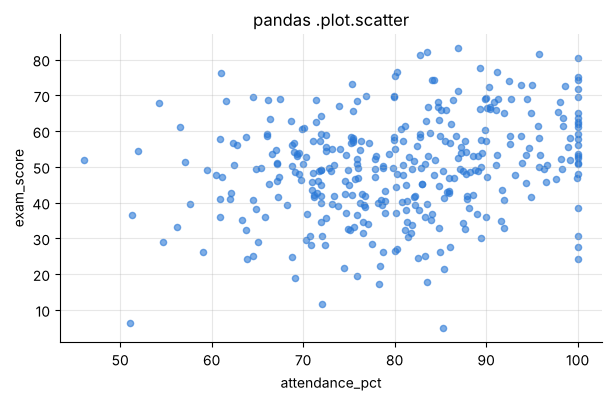

In [17]:
ax = df.plot.scatter(x="attendance_pct", y="exam_score", alpha=0.6)
ax.set_title("pandas .plot.scatter")
plt.show()

(**Seaborn** — `import seaborn as sns` — is a library on top of Matplotlib for statistical plots such as `sns.pairplot`, `sns.heatmap`, `sns.violinplot`. It is worth exploring once you know the basics here.)

## 9.11 A decision boundary

To see how a classifier splits the feature space, evaluate it on a fine **grid** of points and colour each grid cell by its prediction. Here a hand-made logistic model:

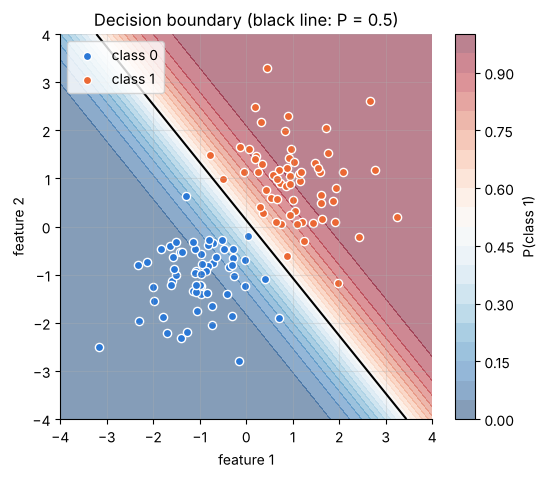

In [18]:
rng = np.random.default_rng(1)
X0 = rng.normal([-1, -1], 0.8, size=(60, 2))
X1 = rng.normal([1.2, 1.0], 0.8, size=(60, 2))

w, b = np.array([1.8, 1.5]), -0.2                  # pretend these were learned
xx, yy = np.meshgrid(np.linspace(-4, 4, 300), np.linspace(-4, 4, 300))
grid = np.column_stack([xx.ravel(), yy.ravel()])   # (90000, 2) points
prob = 1 / (1 + np.exp(-(grid @ w + b)))
prob = prob.reshape(xx.shape)

fig, ax = plt.subplots(figsize=(6, 5))
cf = ax.contourf(xx, yy, prob, levels=20, cmap="RdBu_r", alpha=0.5, vmin=0, vmax=1)
ax.contour(xx, yy, prob, levels=[0.5], colors="black", linewidths=1.5)
ax.scatter(X0[:, 0], X0[:, 1], label="class 0", edgecolor="white", s=35, color=COLORS[0])
ax.scatter(X1[:, 0], X1[:, 1], label="class 1", edgecolor="white", s=35, color=COLORS[1])
fig.colorbar(cf, ax=ax, label="P(class 1)")
ax.set_xlabel("feature 1")
ax.set_ylabel("feature 2")
ax.set_title("Decision boundary (black line: P = 0.5)")
ax.legend(loc="upper left")
plt.show()

## 9.12 Saving figures

In [19]:
fig, ax = plt.subplots()
ax.plot(epochs, train_loss, label="train")
ax.plot(epochs, val_loss, label="validation")
ax.set_xlabel("epoch")
ax.set_ylabel("loss")
ax.legend()
fig.savefig("training_curve.png", dpi=200, bbox_inches="tight")   # PNG for slides/web
fig.savefig("training_curve.pdf", bbox_inches="tight")            # vector PDF for LaTeX reports
plt.close(fig)
print("saved")

saved


## 9.13 Design checklist

* **Choose the chart by the question:** trend → line; relationship → scatter; distribution → histogram/box plot; comparison across categories → bar; matrix → heatmap.
* **Label everything:** axis labels with units, a title that states the finding, a legend when there are 2+ series.
* **Bars start at zero.** Lines may zoom in.
* **One measure per y-axis**; use separate panels for different units.
* **Colour with purpose:** categorical colours for groups, sequential for magnitude, diverging around a meaningful centre. Avoid rainbow colormaps; don't rely on colour alone (also use line styles, markers or labels).
* **Remove clutter:** light grids, no 3-D effects, no unnecessary decoration.

---

## Summary

* `fig, ax = plt.subplots()`; draw with `ax.plot`, `ax.scatter`, `ax.hist`, `ax.bar`/`barh`, `ax.boxplot`, `ax.imshow`, `ax.contourf`.
* Customise with `ax.set_xlabel/ylabel/title/xlim/ylim`, `ax.legend()`, `fig.colorbar`, `plt.tight_layout()`.
* Multi-panel: `plt.subplots(rows, cols)`; iterate with `axes.ravel()`.
* Save with `fig.savefig(..., dpi=200, bbox_inches="tight")`.

---

## Exercises

Solutions: `solutions/09_matplotlib_solutions.ipynb`. Use `../data/student_performance.csv` where needed.

**Exercise 9.1 — Function plot.**
Plot $f(x) = x^2$, $g(x) = x^3$ and $h(x) = e^x$ for $x \in [-2, 2]$ on the same axes, with different line styles, a legend, axis labels, a title, and y-limits of [−5, 8].

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# Your code here

**Exercise 9.2 — Learning-rate comparison.**
Run gradient descent on $f(w) = (w-3)^2$ starting at $w=0$ for 30 steps, with learning rates `0.01`, `0.1`, `0.5` and `0.95`. Plot the loss per step for each learning rate on one chart, with a **log scale** on the y-axis (`ax.set_yscale("log")`). Which learning rate converges fastest? What happens with 0.95?

In [21]:
# Your code here

**Exercise 9.3 — Exploring the dataset.**
Create a 1×3 figure: (a) a histogram of `attendance_pct`; (b) a scatter plot of `prior_gpa` vs `exam_score`; (c) a box plot of `exam_score` for full-time vs part-time students (clean `study_mode` first). Give each panel a title and axis labels.

In [22]:
# Your code here

**Exercise 9.4 — Bar chart with labels.**
Plot the **average hours studied per programme** as a horizontal bar chart, sorted from highest to lowest, with each bar labelled with its value (1 decimal).

In [23]:
# Your code here

**Exercise 9.5 — Predicted vs actual.**
Fit a straight line to predict `exam_score` from `hours_studied` using `np.polyfit(x, y, 1)`. Produce a 1×2 figure: (a) the data with the fitted line drawn on top; (b) a **residual plot** (residual = actual − predicted, on the y-axis, vs predicted), with a horizontal line at 0. What would a pattern in the residual plot tell you?

In [24]:
# Your code here

**Exercise 9.6 — Confusion matrix heatmap (challenge).**
Given the confusion matrix below (rows = true class, columns = predicted class), draw it with `imshow` using a **sequential** colormap, write the count in each cell (white text on dark cells, black on light cells), label the axes with the class names, and save the figure as `confusion_matrix.png`.

In [25]:
cm = np.array([[50, 3, 2],
               [4, 41, 5],
               [1, 6, 38]])
classes = ["setosa", "versicolor", "virginica"]
# Your code here